# 2. Exploratory Data Analysis 

Goal: understand sales, customers, products, delivery, reviews and payments, and find what matters for predicting repeat purchases.

Data checks (missing values, duplicates, outliers) were done in `1_data_cleaning.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

In [2]:
path = Path(r'C:\Users\EXPRESS\Desktop\E-Commerce-Customer-Value-and-Purchase-Prediction--main\data\processed\parquet')
for file in path.iterdir():
    print(file.name)

olist_customers_dataset.parquet
olist_geolocation_dataset.parquet
olist_orders_dataset.parquet
olist_order_items_dataset.parquet
olist_order_payments_dataset.parquet
olist_order_reviews_dataset.parquet
olist_products_dataset.parquet
olist_sellers_dataset.parquet
product_category_name_translation.parquet


In [3]:
customers = pd.read_parquet(f'{path}/olist_customers_dataset.parquet')
geolocation = pd.read_parquet(f'{path}/olist_geolocation_dataset.parquet')
orders = pd.read_parquet(f'{path}/olist_orders_dataset.parquet')
order_items = pd.read_parquet(f'{path}/olist_order_items_dataset.parquet')
payments = pd.read_parquet(f'{path}/olist_order_payments_dataset.parquet')
reviews = pd.read_parquet(f'{path}/olist_order_reviews_dataset.parquet')
products = pd.read_parquet(f'{path}/olist_products_dataset.parquet')
sellers = pd.read_parquet(f'{path}/olist_sellers_dataset.parquet')
category_translation = pd.read_parquet(f'{path}/product_category_name_translation.parquet')

In [4]:
# Creating dictionary containing all tables
data = {'customers': customers,
'geolocation' : geolocation,
'order_items': order_items,
'payments': payments,
'reviews': reviews,
'orders': orders,
'products': products,
'sellers': sellers,
'category_translation': category_translation}


**Delivered orders only.** About 97% of orders are delivered. For spending, purchase gaps, products, delivery and reviews we only use delivered orders, so canceled or unavailable orders do not distort the results.

In [5]:
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()
print('All orders:', len(orders), '| Delivered orders:', len(delivered_orders))

All orders: 99441 | Delivered orders: 96478


## 1. Sales & Order Overview

### 1.1 Order status

,order_status,total_orders,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


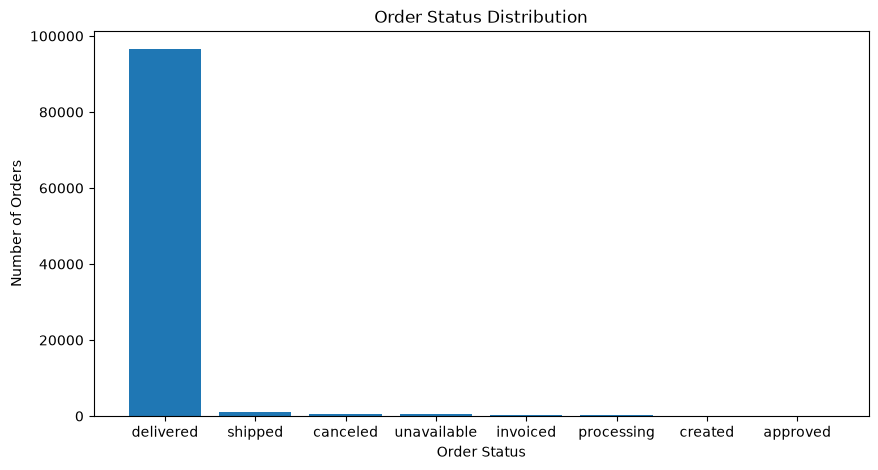

In [6]:
status_distribution = orders['order_status'].value_counts().reset_index()
status_distribution.columns = ['order_status', 'total_orders']
status_distribution['percentage'] = (status_distribution['total_orders'] / status_distribution['total_orders'].sum() * 100).round(2)
display(status_distribution)

plt.figure(figsize=(10, 5))
plt.bar(status_distribution['order_status'], status_distribution['total_orders'])
plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.show()

**Finding:** About 97% of orders are delivered. Shipped, canceled, unavailable and the other statuses are each very small, so they do not change the overall picture.

### 1.2 Monthly orders

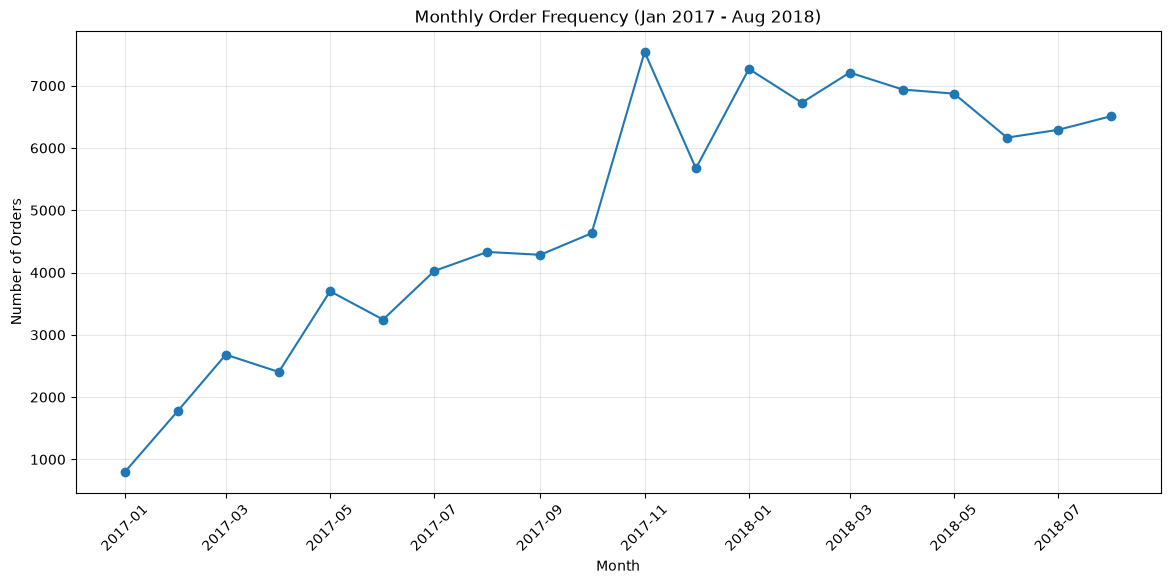

Peak month:
purchase_month    2017-11-01 00:00:00
total_orders                     7544
Name: 13, dtype: object


In [7]:
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()
monthly_orders = orders.groupby('purchase_month')['order_id'].nunique().reset_index(name='total_orders')

# keep only complete months (Jan 2017 to Aug 2018)
monthly_orders = monthly_orders[(monthly_orders['purchase_month'] >= '2017-01-01') &
                                (monthly_orders['purchase_month'] <= '2018-08-01')]

plt.figure(figsize=(14, 6))
plt.plot(monthly_orders['purchase_month'], monthly_orders['total_orders'], marker='o')
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.title('Monthly Order Frequency (Jan 2017 - Aug 2018)')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

print('Peak month:')
print(monthly_orders.loc[monthly_orders['total_orders'].idxmax()])

**Finding:** Orders grew steadily from January 2017, jumped to a peak of about 7,500 in November 2017 (likely Black Friday), then stayed around 6,000 to 7,000 per month through August 2018. The months before 2017 and after August 2018 were removed because their data is incomplete.

### 1.3 Monthly revenue

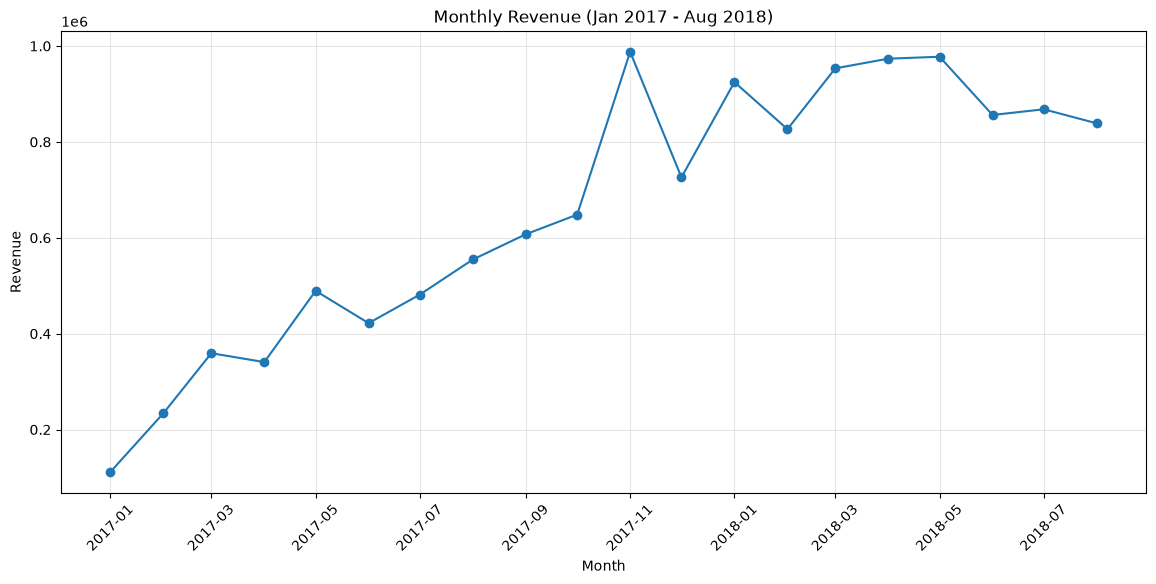

Peak month:
purchase_month    2017-11-01 00:00:00
revenue                     987765.37
Name: 13, dtype: object


In [8]:
# revenue = sum of item prices per delivered order
order_revenue = order_items.groupby('order_id')['price'].sum().reset_index(name='revenue')
revenue = delivered_orders.merge(order_revenue, on='order_id', how='inner')
revenue['purchase_month'] = revenue['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

monthly_revenue = revenue.groupby('purchase_month')['revenue'].sum().reset_index()
monthly_revenue = monthly_revenue[(monthly_revenue['purchase_month'] >= '2017-01-01') &
                                  (monthly_revenue['purchase_month'] <= '2018-08-01')]

plt.figure(figsize=(14, 6))
plt.plot(monthly_revenue['purchase_month'], monthly_revenue['revenue'], marker='o')
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.title('Monthly Revenue (Jan 2017 - Aug 2018)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

print('Peak month:')
print(monthly_revenue.loc[monthly_revenue['revenue'].idxmax()])

**Finding:** Revenue follows the same trend as orders: it grows through 2017, peaks in November 2017 (about 988,000), and then stays between roughly 830,000 and 980,000 per month in 2018.

## 2. Customer Analysis

### 2.1 Customers by state

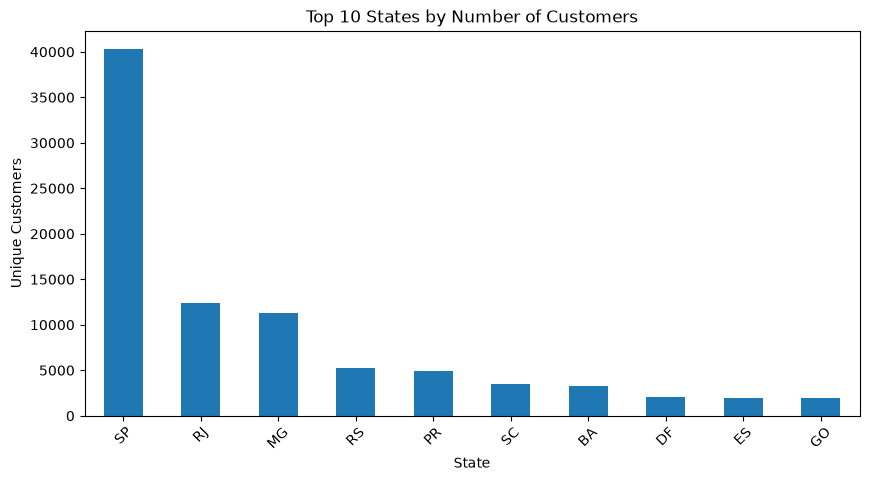

customer_state
SP    41.9
RJ    12.9
MG    11.7
RS     5.5
PR     5.1
SC     3.7
BA     3.4
DF     2.2
ES     2.0
GO     2.0
Name: customer_unique_id, dtype: float64


In [9]:
# number of unique customers per state
unique_customers = customers['customer_unique_id'].nunique()
top_states = (customers.groupby('customer_state')['customer_unique_id'].nunique()
              .sort_values(ascending=False).head(10))

top_states.plot(kind='bar', figsize=(10, 5))
plt.title('Top 10 States by Number of Customers')
plt.xlabel('State')
plt.ylabel('Unique Customers')
plt.xticks(rotation=45)
plt.show()

print((top_states / unique_customers * 100).round(1))

**Finding:** São Paulo (SP) dominates with about 42% of all customers (roughly 40,000). RJ (about 13%) and MG (about 12%) follow, and every other state is below 6%.

### 2.2 Customers by city

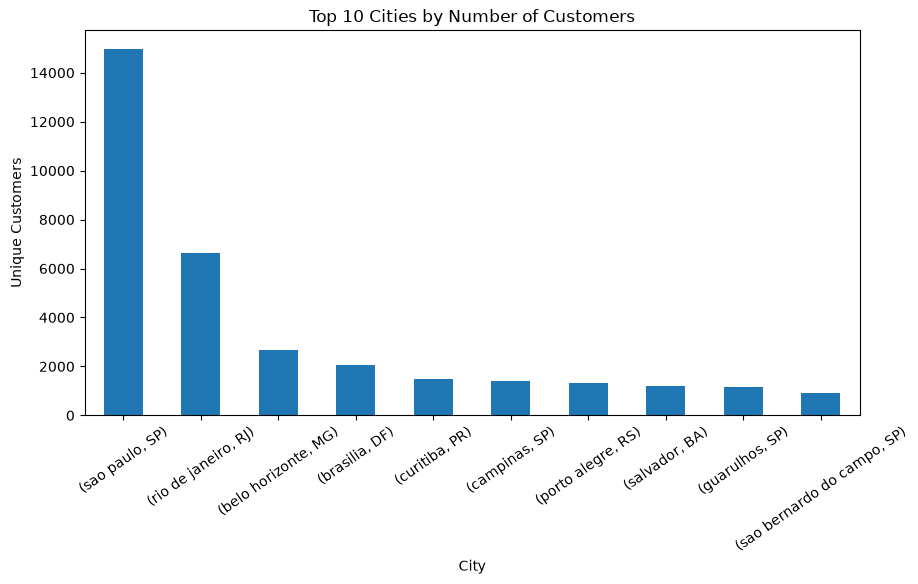

In [10]:
# number of unique customers in each city
top_cities = (customers.groupby(['customer_city', 'customer_state'])['customer_unique_id'].nunique()
              .sort_values(ascending=False).head(10))

top_cities.plot(kind='bar', figsize=(10, 5))
plt.title('Top 10 Cities by Number of Customers')
plt.xlabel('City')
plt.ylabel('Unique Customers')
plt.xticks(rotation=35)
plt.show()

**Finding:** Sao Paulo is the top city, followed by Rio de Janeiro and Belo Horizonte, matching the state results.

### 2.3 Orders per customer

In [11]:
# link delivered orders to the real customer (customer_unique_id)
customer_orders = delivered_orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')

orders_per_customer = (customer_orders.groupby('customer_unique_id')['order_id']
                       .nunique().reset_index(name='total_orders'))
orders_per_customer['total_orders'].describe()

count    93358.000000
mean         1.033420
std          0.209097
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         15.000000
Name: total_orders, dtype: float64

**Finding:** The average customer placed about 1.03 orders and the median is 1. The most any customer placed is 15, but that is very rare.

### 2.4 Customer spending

In [12]:
order_spending = (order_items.groupby('order_id')
                  .agg(total_spending=('price', 'sum'), total_freight=('freight_value', 'sum'))
                  .reset_index())

customer_spending = customer_orders.merge(order_spending, on='order_id', how='left')

customer_total_spending = (customer_spending.groupby('customer_unique_id')
                           .agg(total_spending=('total_spending', 'sum'),
                                total_orders=('order_id', 'nunique'))
                           .reset_index())

customer_total_spending['total_spending'].describe()

count    93358.000000
mean       141.621480
std        215.694014
min          0.850000
25%         47.650000
50%         89.730000
75%        154.737500
max      13440.000000
Name: total_spending, dtype: float64

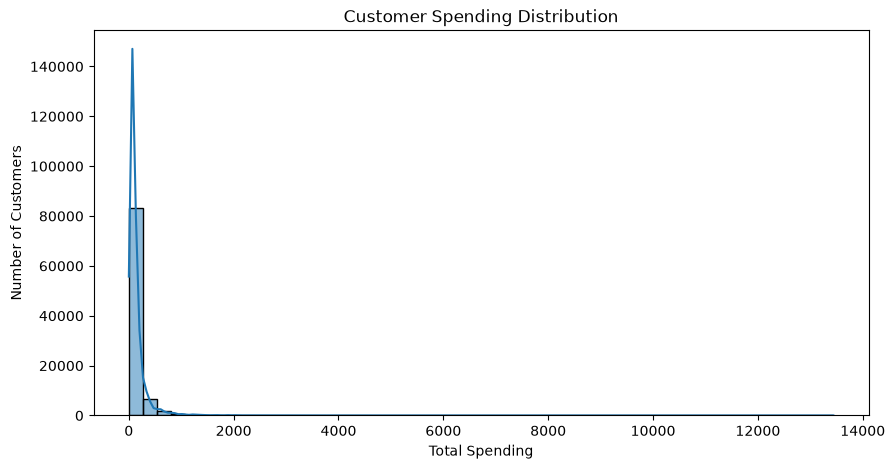

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(customer_total_spending['total_spending'], bins=50, kde=True)
plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')
plt.show()

**Finding:** Spending is right-skewed. The median customer spends about 90, the mean is about 140, and a few big spenders reach over 13,000.

**Modelling note:** use the median or a log transform for spending.

### 2.5 Repeat vs. one-time customers

In [14]:
customer_behavior = customer_total_spending.copy()
customer_behavior['customer_type'] = np.where(customer_behavior['total_orders'] > 1,
                                              'Repeat Customer', 'One-Time Customer')

customer_comparison = customer_behavior.groupby('customer_type').agg(
    customers=('customer_unique_id', 'count'),
    avg_spending=('total_spending', 'mean'),
    median_spending=('total_spending', 'median'),
    avg_orders=('total_orders', 'mean'))
customer_comparison['percentage'] = (customer_comparison['customers'] / customer_comparison['customers'].sum() * 100).round(2)
customer_comparison

,customers,avg_spending,median_spending,avg_orders,percentage
customer_type,,,,,
One-Time Customer,90557,137.958295,86.96,1.000000,97.0
Repeat Customer,2801,260.053106,182.10,2.113888,3.0


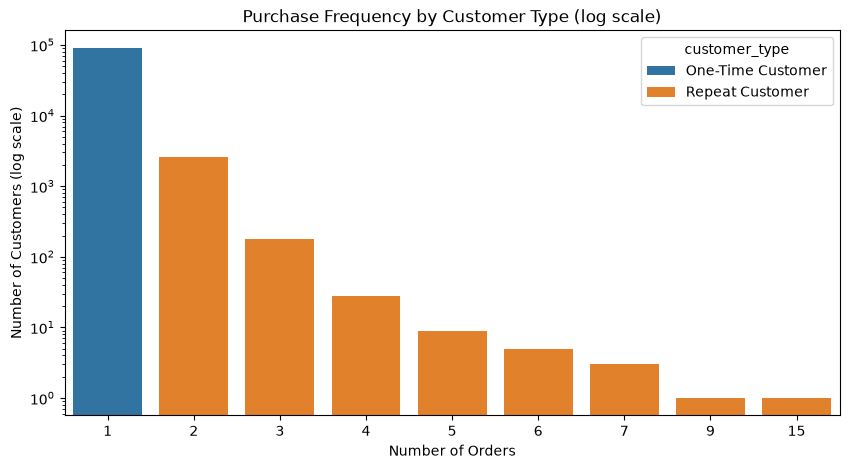

In [15]:
plt.figure(figsize=(10, 5))
sns.countplot(data=customer_behavior, x='total_orders', hue='customer_type')
plt.yscale('log')   # log scale so the small repeat groups are visible
plt.title('Purchase Frequency by Customer Type (log scale)')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers (log scale)')
plt.show()

**Finding:** About 97% of customers (90,557) bought only once and only about 3% (2,801) came back. Repeat customers spend roughly twice as much (average about 260, median about 182) as one-time customers (average about 138, median about 87).

**Modelling note:** the repeat-purchase target will be heavily imbalanced (about 97% vs. 3%), so accuracy alone will be misleading. Use recall, precision, F1 or AUC, and consider class weights or resampling.

### 2.6 Time between purchases

count    3120.000000
mean       78.780449
std       107.196623
min         0.000000
25%         0.000000
50%        29.000000
75%       121.000000
max       608.000000
Name: days_between_purchases, dtype: float64
Same-day repeat orders (%): 29.6


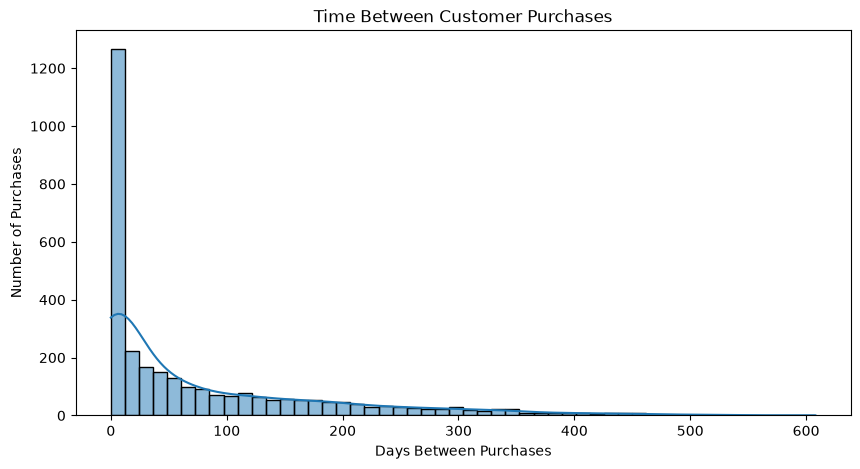

In [16]:
# sort each customer's orders by date and calculate the gap between consecutive orders
customer_orders = customer_orders.sort_values(['customer_unique_id', 'order_purchase_timestamp'])
customer_orders['days_between_purchases'] = (customer_orders.groupby('customer_unique_id')
                                             ['order_purchase_timestamp'].diff().dt.days)

purchase_intervals = customer_orders[customer_orders['days_between_purchases'].notna()]
print(purchase_intervals['days_between_purchases'].describe())
print('Same-day repeat orders (%):',
      round((purchase_intervals['days_between_purchases'] == 0).mean() * 100, 1))

plt.figure(figsize=(10, 5))
sns.histplot(purchase_intervals['days_between_purchases'], bins=50, kde=True)
plt.title('Time Between Customer Purchases')
plt.xlabel('Days Between Purchases')
plt.ylabel('Number of Purchases')
plt.show()

**Finding:** About 30% of repeat orders happen on the same day as the previous order, then the count drops quickly with a long tail up to about 600 days. The median gap is 29 days and the average is about 79 days.

**Note:** the same-day orders are probably customers placing a second order right after the first (for example, buying items separately), not true returning customers. For modelling, consider defining a repeat purchase as an order placed at least a few days after the first one.

## 3. Product Analysis

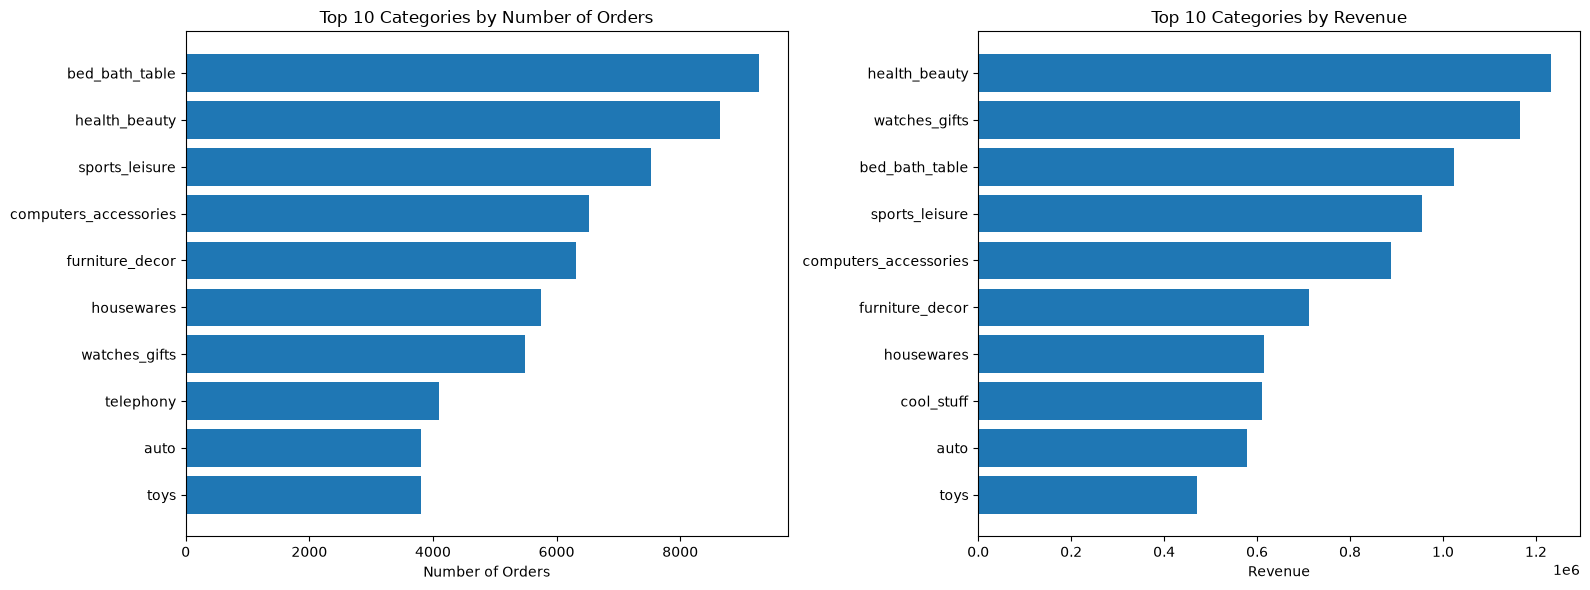

In [17]:
# attach the English category name to each delivered order item
delivered_items = order_items[order_items['order_id'].isin(delivered_orders['order_id'])]

items_category = (delivered_items
                  .merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
                  .merge(category_translation, on='product_category_name', how='left'))

# use the English name; fall back to the original name, then 'unknown'
items_category['category'] = (items_category['product_category_name_english']
                              .fillna(items_category['product_category_name'])
                              .fillna('unknown'))

category_summary = (items_category.groupby('category')
                    .agg(total_orders=('order_id', 'nunique'), total_revenue=('price', 'sum'))
                    .reset_index())

top_by_orders = category_summary.nlargest(10, 'total_orders').iloc[::-1]
top_by_revenue = category_summary.nlargest(10, 'total_revenue').iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top_by_orders['category'], top_by_orders['total_orders'])
axes[0].set_title('Top 10 Categories by Number of Orders')
axes[0].set_xlabel('Number of Orders')
axes[1].barh(top_by_revenue['category'], top_by_revenue['total_revenue'])
axes[1].set_title('Top 10 Categories by Revenue')
axes[1].set_xlabel('Revenue')
plt.tight_layout()
plt.show()

**Finding:** The top categories by orders are bed_bath_table, health_beauty and sports_leisure. By revenue the leaders are health_beauty, watches_gifts and bed_bath_table. Watches_gifts is only 7th by orders but 2nd by revenue, so it sells fewer but more expensive items.

## 4. Delivery Analysis

### 4.1 Delivery time

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64


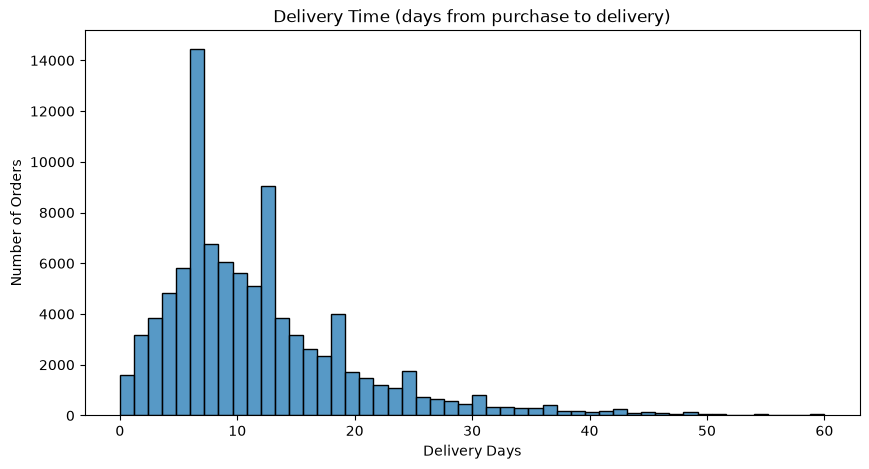

In [18]:
# delivered orders that have a delivery date
delivery = delivered_orders.dropna(subset=['order_delivered_customer_date']).copy()
delivery['delivery_days'] = (delivery['order_delivered_customer_date'] - delivery['order_purchase_timestamp']).dt.days
print(delivery['delivery_days'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(delivery['delivery_days'], bins=50, binrange=(0, 60))   # zoomed to 0-60 days
plt.title('Delivery Time (days from purchase to delivery)')
plt.xlabel('Delivery Days')
plt.ylabel('Number of Orders')
plt.show()

**Finding:** Orders take about 12 days on average to arrive (median 10 days). About 75% of orders arrive within 15 days, but a small number take much longer (up to 209 days).

### 4.2 Late vs. on-time deliveries

is_late
False    93.23
True      6.77
Name: proportion, dtype: float64
count    89936.000000
mean        13.510263
std          7.495949
min          0.000000
25%          8.000000
50%         13.000000
75%         17.000000
max        147.000000
dtype: float64


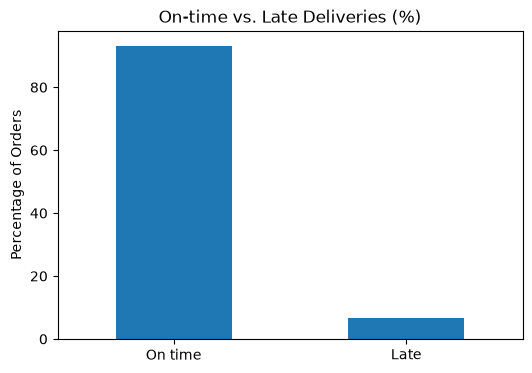

In [19]:
# late = delivered after the estimated delivery date (compared by date, not time of day)
delivery['is_late'] = (delivery['order_delivered_customer_date'].dt.normalize() >
                       delivery['order_estimated_delivery_date'])

late_share = (delivery['is_late'].value_counts(normalize=True) * 100).round(2)
print(late_share)

# how many days before the estimate do on-time orders arrive?
days_early = (delivery['order_estimated_delivery_date'] - delivery['order_delivered_customer_date'].dt.normalize()).dt.days
print(days_early[~delivery['is_late']].describe())

late_share.rename(index={False: 'On time', True: 'Late'}).plot(kind='bar', figsize=(6, 4))
plt.title('On-time vs. Late Deliveries (%)')
plt.xlabel('')
plt.ylabel('Percentage of Orders')
plt.xticks(rotation=0)
plt.show()

**Finding:** About 6.8% of delivered orders arrive late. On-time orders usually arrive about 13 days before the estimated date, so Olist's delivery estimates are conservative.

## 5. Reviews

### 5.1 Review score distribution

review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: count, dtype: float64


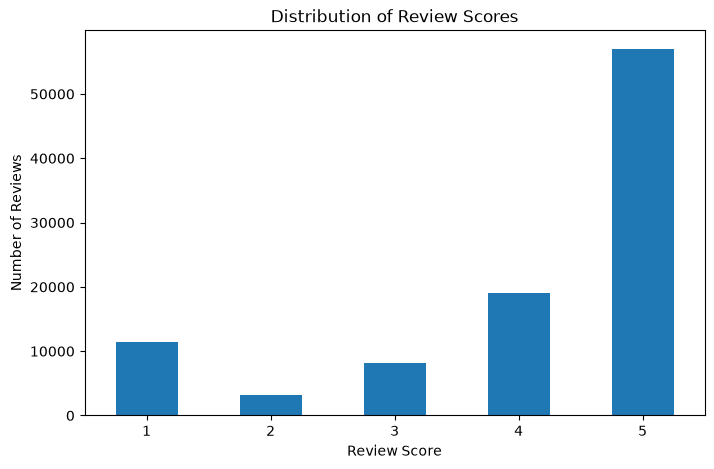

In [20]:
# keep one review per order (cleaning found duplicate review IDs)
reviews_clean = reviews.drop_duplicates('order_id').copy()
reviews_clean['review_score'] = reviews_clean['review_score'].astype('int64')

score_counts = reviews_clean['review_score'].value_counts().sort_index()
print((score_counts / score_counts.sum() * 100).round(1))

score_counts.plot(kind='bar', figsize=(8, 5))
plt.title('Distribution of Review Scores')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

**Finding:** Reviews are mostly positive: about 58% are five-star and about 19% are four-star. One-star is the next largest group (about 11%), so unhappy customers are a clear minority but not tiny.

### 5.2 Reviews vs. late delivery

,mean,count
is_late,,
On time,4.29,89443
Late,2.27,6381


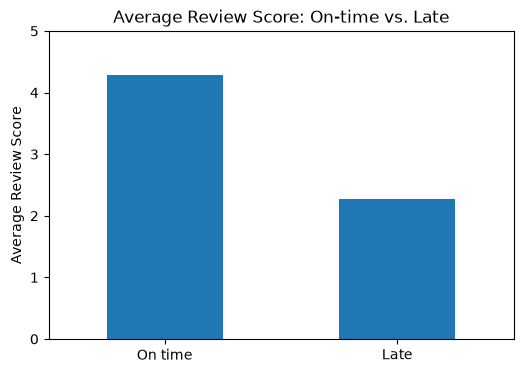

In [26]:
review_delivery = reviews_clean.merge(delivery[['order_id', 'is_late']], on='order_id', how='inner')

late_vs_score = (review_delivery.groupby('is_late')['review_score'].agg(['mean', 'count']).round(2).rename(index={False: 'On time', True: 'Late'}))
display(late_vs_score)

late_vs_score['mean'].plot(kind='bar', figsize=(6, 4))
plt.title('Average Review Score: On-time vs. Late')
plt.xlabel('')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

**Finding:** On-time orders average 4.29 stars, while late orders average only 2.27 stars (a drop of about 2 stars). Late delivery clearly hurts customer satisfaction, even though only about 7% of orders are late.

## 6. Payments

payment_type
credit_card    73.9
boleto         19.0
voucher         5.6
debit_card      1.5
Name: proportion, dtype: float64


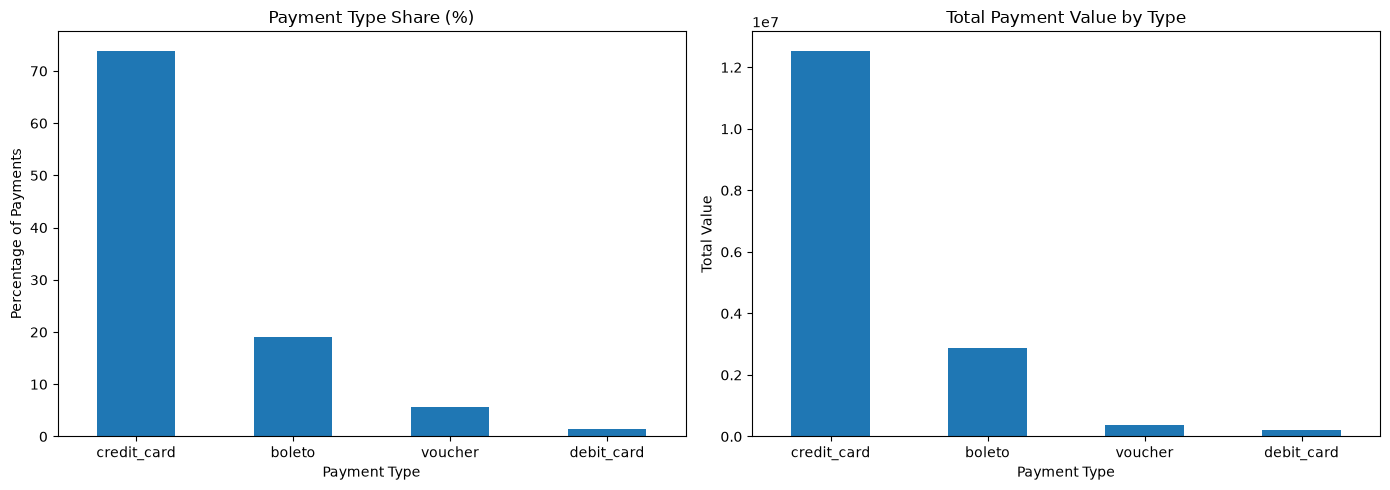

In [22]:
# remove the 3 'not_defined' payments found during cleaning
payments_clean = payments[payments['payment_type'] != 'not_defined']

type_share = (payments_clean['payment_type'].value_counts(normalize=True) * 100).round(1)
type_value = payments_clean.groupby('payment_type')['payment_value'].sum().sort_values(ascending=False)
print(type_share)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
type_share.plot(kind='bar', ax=axes[0])
axes[0].set_title('Payment Type Share (%)')
axes[0].set_xlabel('Payment Type')
axes[0].set_ylabel('Percentage of Payments')
axes[0].tick_params(axis='x', rotation=0)
type_value.plot(kind='bar', ax=axes[1])
axes[1].set_title('Total Payment Value by Type')
axes[1].set_xlabel('Payment Type')
axes[1].set_ylabel('Total Value')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

count    103881.000000
mean          2.853457
std           2.687068
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max          24.000000
Name: payment_installments, dtype: float64


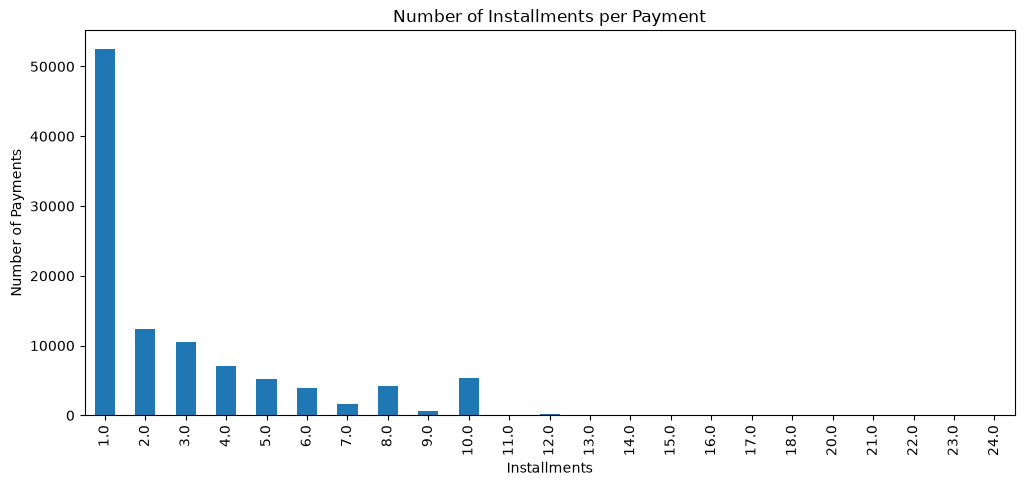

In [23]:
print(payments_clean['payment_installments'].describe())

payments_clean['payment_installments'].value_counts().sort_index().plot(kind='bar', figsize=(12, 5))
plt.title('Number of Installments per Payment')
plt.xlabel('Installments')
plt.ylabel('Number of Payments')
plt.show()

**Finding:** Credit card is used in about 74% of payments, followed by boleto (about 19%), voucher (about 6%) and debit card (about 1.5%). Most payments are made in 1 installment (median 1), but 25% use 4 or more, the average is about 2.9, and the maximum is 24.

## 7. Key Findings and Modelling Notes

1. **Almost no repeat buying:** only about 3% of customers ordered more than once, so the target is highly imbalanced.
2. **Same-day repeats:** about 30% of repeat orders happen on the same day as the previous one, so the definition of a "repeat purchase" needs care.
3. **Repeat customers are more valuable:** they spend about twice as much per customer as one-time customers.
4. **Strong geographic concentration:** SP alone holds about 42% of customers, so state could be a useful feature.
5. **Growth then plateau:** orders grew through 2017 (peak in November 2017) and stayed flat at about 6,000 to 7,000 per month in 2018. Incomplete months were excluded.
6. **Spending is skewed:** use the median or a log transform when modelling.
7. **Products:** bed_bath_table, health_beauty and sports_leisure lead by orders; health_beauty, watches_gifts and bed_bath_table lead by revenue.
8. **Delivery:** about 6.8% of orders arrive late, and average delivery takes about 12 days (median 10).
9. **Reviews:** late delivery lowers the average score from 4.29 to 2.27, so delivery time and lateness are good candidate features.
10. **Payments:** credit card dominates (about 74%), followed by boleto (about 19%). Most payments use 1 installment.